# Qiskit Fall Fest 2026 — Challenge 3: Can You Change the Correlation?
**IBM Quantum | Vishnu Institute of Technology**

## Aim
Start from the Bell-state circuit (`H` on qubit 0, then `CX`), where the two qubits always agree. Then **add one gate** and see whether we can change the relationship between the two measured bits. Both circuits run for **100 shots** on 2 qubits, and we compare them with histograms.

## 1. Setup
Run the install cell once if Qiskit is missing (works on Google Colab too). The experiments run on the local Aer simulator, and the last section optionally repeats them on a real IBM Quantum device.

In [ ]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
OUTCOMES = ["00", "01", "10", "11"]
sim = AerSimulator()

def with_measurement(gates):
    """Put a gate-only 2-qubit circuit into a 2-qubit / 2-bit circuit and measure both qubits."""
    qc = QuantumCircuit(2, 2)
    qc.compose(gates, inplace=True)
    qc.measure([0, 1], [0, 1])
    return qc

def run(qc):
    """Execute for 100 shots; always return all four outcomes (missing ones count as 0)."""
    counts = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()
    return {k: counts.get(k, 0) for k in OUTCOMES}

def exact_counts(gates):
    """Ideal (noise-free) expected number of shots per outcome, from the circuit's quantum state."""
    p = Statevector.from_instruction(gates).probabilities_dict()
    return {k: SHOTS * float(p.get(k, 0)) for k in OUTCOMES}

def agree(counts):
    """Number of shots where both qubits gave the same bit (00 or 11)."""
    return counts["00"] + counts["11"]

print(f"Ready: {SHOTS} shots per circuit on {sim.name}")

Ready: 100 shots per circuit on aer_simulator


## 2. Reading the results
Qiskit writes each outcome as two bits in the order **q1 q0**. For example `01` means qubit 1 gave `0` and qubit 0 gave `1`. Since all we care about here is whether the two bits are *equal or different*, this order does not change the conclusions.

## 3. Predictions (written before running)

| Circuit | Gates | Expected outcomes | Why |
|---|---|---|---|
| Original (Bell state) | H on q0, CX(q0 → q1) | about 50 × `00`, 50 × `11`; no `01` or `10` | H puts q0 in superposition, CX copies it onto q1, so the two bits always agree |
| Modified | H on q0, CX(q0 → q1), **X on q1** | about 50 × `01`, 50 × `10`; no `00` or `11` | X flips q1 after the CX, so the two bits now always disagree |

**Will the two qubits still produce the same outcomes?** In the modified circuit, no: they will always be *different*. The outcomes are still perfectly correlated, just the opposite way round (anti-correlated).
**Will `00` and `11` dominate?** In the original yes, in the modified circuit no, they disappear.
**Could `01` and `10` become more frequent?** Yes, they become the only outcomes, at about 50 each.

## 4. Original circuit — the Bell state

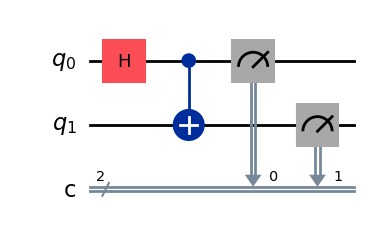

In [3]:
bell_gates = QuantumCircuit(2)
bell_gates.h(0)
bell_gates.cx(0, 1)

qc_bell = with_measurement(bell_gates)
qc_bell.draw("mpl")

Original circuit counts: {'00': 43, '01': 0, '10': 0, '11': 57}
Both qubits agree in 100 of 100 shots


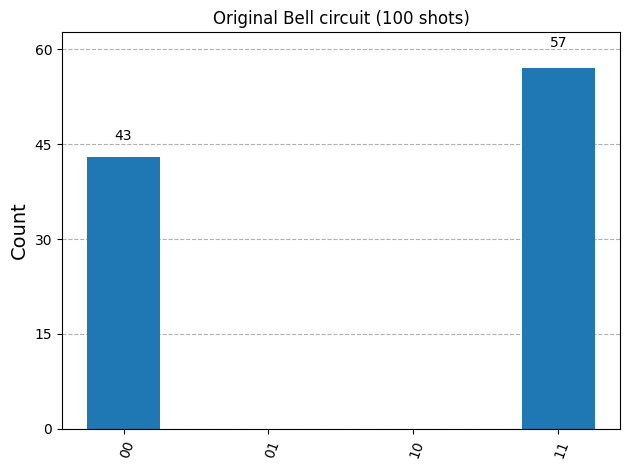

In [4]:
counts_bell = run(qc_bell)
print("Original circuit counts:", counts_bell)
print("Both qubits agree in", agree(counts_bell), "of", SHOTS, "shots")
plot_histogram(counts_bell, title="Original Bell circuit (100 shots)")

## 5. Modified circuit — add one X gate on qubit 1
The only change is one extra gate after the CX. The circuit now has 3 gates before measurement (limit: 4).

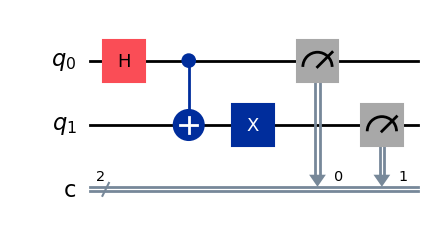

In [5]:
mod_gates = QuantumCircuit(2)
mod_gates.h(0)
mod_gates.cx(0, 1)
mod_gates.x(1)          # <- the one added gate

qc_mod = with_measurement(mod_gates)
qc_mod.draw("mpl")

Modified circuit counts: {'00': 0, '01': 54, '10': 46, '11': 0}
Both qubits agree in 0 of 100 shots


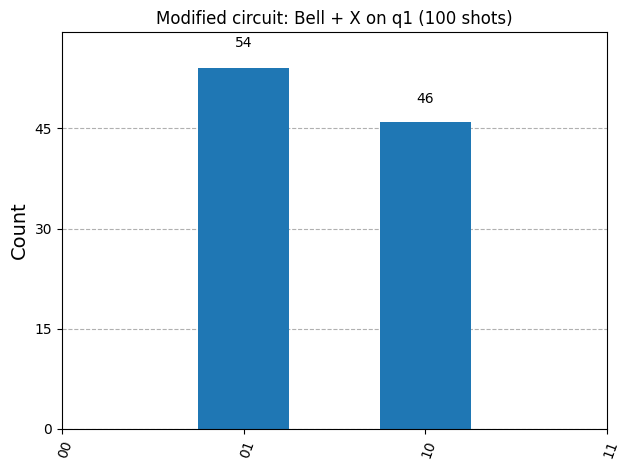

In [6]:
counts_mod = run(qc_mod)
print("Modified circuit counts:", counts_mod)
print("Both qubits agree in", agree(counts_mod), "of", SHOTS, "shots")
plot_histogram(counts_mod, title="Modified circuit: Bell + X on q1 (100 shots)")

## 6. Comparing the original and modified circuits

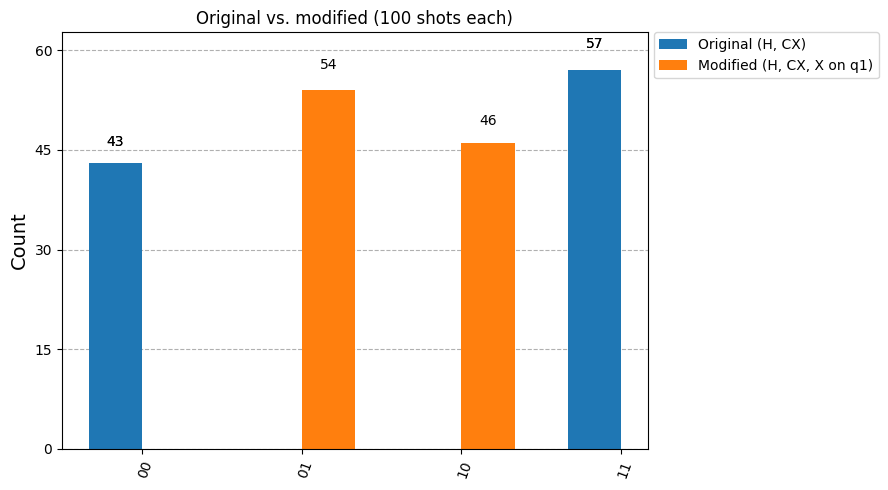

In [7]:
plot_histogram([counts_bell, counts_mod],
               legend=["Original (H, CX)", "Modified (H, CX, X on q1)"],
               title="Original vs. modified (100 shots each)", figsize=(9, 5))

In [8]:
print(f"{'Circuit':<28}{'00':>5}{'01':>5}{'10':>5}{'11':>5}   Agree (same bits)")
print("-" * 62)
for name, cnt in [("Original (H, CX)", counts_bell), ("Modified (H, CX, X on q1)", counts_mod)]:
    print(f"{name:<28}{cnt['00']:>5}{cnt['01']:>5}{cnt['10']:>5}{cnt['11']:>5}   {agree(cnt)} / {SHOTS}")

Circuit                        00   01   10   11   Agree (same bits)
--------------------------------------------------------------
Original (H, CX)               43    0    0   57   100 / 100
Modified (H, CX, X on q1)       0   54   46    0   0 / 100


## 7. Other single-gate changes (extra exploration)
Each circuit below is the Bell circuit plus **one different added gate**, so we can see which kinds of gate change the correlation and which do not.

| Added gate | Prediction |
|---|---|
| X on q0 | bits now always differ (`01` / `10`), same effect as X on q1 |
| Z on q0 | no visible change, `00` / `11` still. Z only changes the *phase*, not the probabilities |
| H on q1 | all four outcomes appear, about 25 each. The correlation is gone |

Circuit              00   01   10   11   Agree
Bell + X on q0        0   47   53    0   0 / 100


Bell + Z on q0       50    0    0   50   100 / 100
Bell + H on q1       27   27   25   21   48 / 100


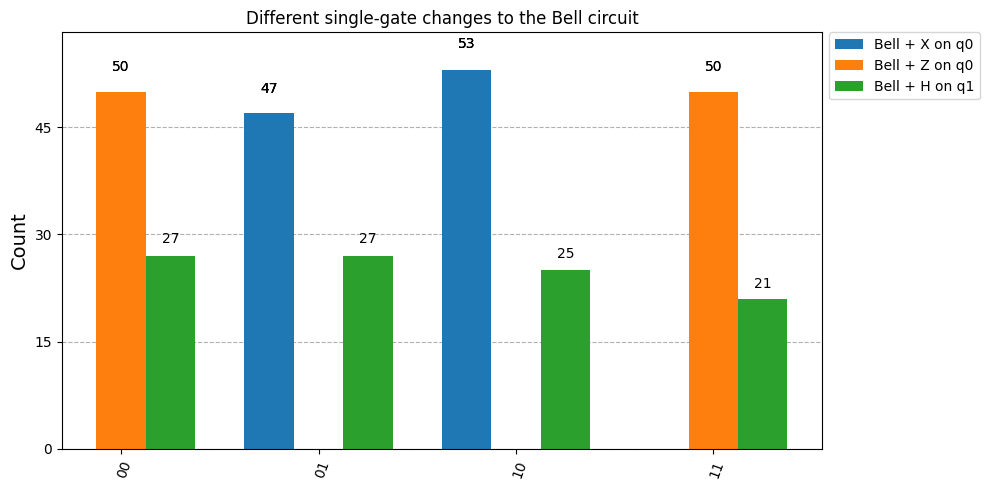

In [9]:
extras = {}

g = bell_gates.copy(); g.x(0); extras["Bell + X on q0"] = g
g = bell_gates.copy(); g.z(0); extras["Bell + Z on q0"] = g
g = bell_gates.copy(); g.h(1); extras["Bell + H on q1"] = g

extra_counts = {}
print(f"{'Circuit':<18}{'00':>5}{'01':>5}{'10':>5}{'11':>5}   Agree")
for name, gates in extras.items():
    cnt = run(with_measurement(gates))
    extra_counts[name] = cnt
    print(f"{name:<18}{cnt['00']:>5}{cnt['01']:>5}{cnt['10']:>5}{cnt['11']:>5}   {agree(cnt)} / {SHOTS}")

plot_histogram(list(extra_counts.values()), legend=list(extra_counts.keys()),
               title="Different single-gate changes to the Bell circuit", figsize=(10, 5))

## 8. Prediction vs. actual
For every outcome we compare the measured count with the ideal expected count. A result passes when it is within 3 standard deviations (the normal random spread of 100 shots). Outcomes that should never happen must be exactly 0.

In [10]:
all_runs = {
    "Original (H, CX)":          (bell_gates, counts_bell),
    "Modified (+ X on q1)":      (mod_gates,  counts_mod),
}
for name, gates in extras.items():
    all_runs[name] = (gates, extra_counts[name])

print(f"{'Circuit':<24}{'Expected 00/01/10/11':<26}{'Measured':<20}Pass?")
print("-" * 76)
for name, (gates, meas) in all_runs.items():
    exp = exact_counts(gates)
    ok = True
    for k in OUTCOMES:
        p = exp[k] / SHOTS
        sigma = (SHOTS * p * (1 - p)) ** 0.5
        ok &= abs(meas[k] - exp[k]) <= 3 * sigma + 1e-9
    e = "/".join(f"{exp[k]:.0f}" for k in OUTCOMES)
    m = "/".join(str(meas[k]) for k in OUTCOMES)
    print(f"{name:<24}{e:<26}{m:<20}{'Yes' if ok else 'No'}")

Circuit                 Expected 00/01/10/11      Measured            Pass?
----------------------------------------------------------------------------
Original (H, CX)        50/0/0/50                 43/0/0/57           Yes
Modified (+ X on q1)    0/50/50/0                 0/54/46/0           Yes
Bell + X on q0          0/50/50/0                 0/47/53/0           Yes
Bell + Z on q0          50/0/0/50                 50/0/0/50           Yes
Bell + H on q1          25/25/25/25               27/27/25/21         Yes


## 9. Explanation of the observed change

- **Original circuit:** `H` on qubit 0 creates a superposition, and `CX` makes qubit 1 copy qubit 0. The state is (|00⟩ + |11⟩)/√2, so the two measured bits are always equal. Each of `00` and `11` shows up about half of the time, and `01` / `10` never appear.
- **Modified circuit:** the added `X` gate on qubit 1 flips that qubit's bit after the entanglement is made. The state becomes (|01⟩ + |10⟩)/√2, so the two bits are now always *different*. `01` and `10` appear about half of the time each, and `00` / `11` disappear.
- **Key idea:** the qubits are still perfectly correlated (knowing one bit tells you the other), but the relationship has changed from "same" to "opposite". A single extra gate was enough to change it.
- **Other gates (Section 7):** `Z` only changes the phase, so the measured counts did not change. `H` on qubit 1 breaks the simple correlation completely, giving all four outcomes. So different gates affect the correlation in different ways.

The counts are close to the predictions but not exactly 50/50, because 100 random shots always fluctuate a little.

**Checklist:** 2 qubits ✔  both measured ✔  starts from the Bell circuit ✔  one gate added ✔  at most 4 gates ✔  prediction first ✔  100 shots ✔  histograms and comparison ✔  explanation ✔

## 10. (Optional) Run the original and modified circuits on a real IBM Quantum device

You need an IBM Cloud API key from https://quantum.cloud.ibm.com. Real devices have noise, so a few shots may land on the "wrong" outcomes (for example a few `01` / `10` in the Bell circuit).

**Step 1 (once):** paste your key into the cell below and run it. **Step 2:** delete the key from the cell afterwards so it never ends up in a file you share or upload. If no credentials are saved, the next cell skips the hardware run, so "Run All" still works.

In [11]:
# %pip install -q qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService

IBM_API_KEY  = "PASTE_YOUR_API_KEY_HERE"   # delete after saving
IBM_INSTANCE = ""                          # optional: instance name or CRN

if IBM_API_KEY != "PASTE_YOUR_API_KEY_HERE":
    opts = dict(channel="ibm_quantum_platform", token=IBM_API_KEY,
                overwrite=True, set_as_default=True)
    if IBM_INSTANCE:
        opts["instance"] = IBM_INSTANCE
    QiskitRuntimeService.save_account(**opts)
    print("Credentials saved. Delete your key from this cell now.")
else:
    print("No new key entered; using saved credentials if available.")

No new key entered; using saved credentials if available.


In [12]:
from qiskit_ibm_runtime import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

try:
    service = QiskitRuntimeService()
    hw = service.least_busy(operational=True, simulator=False, min_num_qubits=2)
except Exception as err:
    hw = None
    print("Skipping the hardware run (no usable IBM credentials):", err)

if hw is not None:
    print("Running on:", hw.name)
    hw_labels = ["Original (H, CX)", "Modified (H, CX, X on q1)"]
    pm = generate_preset_pass_manager(backend=hw, optimization_level=0)   # keep gates as written
    job = SamplerV2(mode=hw).run([pm.run(q) for q in (qc_bell, qc_mod)], shots=SHOTS)
    print("Job ID:", job.job_id(), "- waiting for the result ...")
    hw_counts = [p.data.c.get_counts() for p in job.result()]   # register is named 'c' by default
    for label, cnt in zip(hw_labels, hw_counts):
        print(f"{label}: {dict(sorted(cnt.items()))}")
    display(plot_histogram(hw_counts, legend=hw_labels,
                           title=f"IBM hardware ({hw.name}), 100 shots", figsize=(9, 5)))
    # Qiskit rewrites our gates into the device's native gates, so more physical gates run than the 3 we wrote.

Skipping the hardware run (no usable IBM credentials): "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."
